# FinSense — Financial News Sentiment Analysis

Fine-tuning and evaluating financial sentiment models, followed by an experimental financial-news analysis pipeline.

**Run from top to bottom.** All generated files are saved under `FinSense/` in the current working directory (the directory where Python is running). In Colab, this is typically `/content/FinSense/`, which is temporary unless you mount persistent storage. The notebook cannot reliably discover its own `.ipynb` file location.

Install packages from `requirements.txt` before running. Training requires substantial compute; GPU recommended. Saved outputs reflect an earlier execution and are not proof this revised version was rerun.


# T1 — Data Loading & Preprocessing
## # CPCS432 · Financial Sentiment Analysis Project

This notebook prepares the data for training our FinBERT sentiment classifier.

**What we do here:**
- Load two financial sentiment datasets from HuggingFace
- Clean and normalize the text
- Build train / val / test splits
- Compute class weights to handle class imbalance
- Save everything ready for model training (T2)

**Datasets:**
- `FinancialPhraseBank` — 4,846 labeled financial news sentences
- `Twitter Financial News Sentiment` — ~11,900 labeled finance tweets

In [1]:
# Install dependencies once before running this notebook:
# %pip install -r requirements.txt
# In Google Colab, upload requirements.txt or install the listed packages.


## # Config & Seeds

Before anything else we set up:
- **SEED** — fixes all randomness so our splits are identical every run (important for reproducibility in the report)
- **LABEL2ID / ID2LABEL** — maps class names to numbers and back, used everywhere from training to evaluation
- **LABEL_COLORS** — consistent colors across all charts (red = negative, gray = neutral, green = positive)
- **Output folders** — `data/` for CSVs, `figures/` for plots

In [ ]:
import os
from pathlib import Path
import random
import numpy as np

# ── Reproducibility ────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ── Label mappings ─────────────────────────────────────────────
LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL  = {v: k for k, v in LABEL2ID.items()}
LABEL_COLORS = {
    "negative": "#E24B4A",
    "neutral":  "#888780",
    "positive": "#1D9E75"
}

# ── Output folders ─────────────────────────────────────────────
PROJECT_DIR = Path.cwd() / "FinSense"
DATA_DIR = PROJECT_DIR / "data"
MODELS_DIR = PROJECT_DIR / "models"
FIGURES_DIR = PROJECT_DIR / "figures"
LOGS_DIR = PROJECT_DIR / "logs"
for folder in (DATA_DIR, MODELS_DIR, FIGURES_DIR, LOGS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("✓ Config ready")
print(f"  Labels : {LABEL2ID}")
print(f"  Outputs: data/  figures/")

## #  Load FinancialPhraseBank

We first try the original `takala/financial_phrasebank` dataset but it uses a legacy
loading script that the current HuggingFace API no longer supports.

We switch to `descartes100/enhanced-financial-phrasebank`, a clean Parquet mirror
of the same data. Here we load it and inspect its structure before doing anything else.

In [3]:
from datasets import load_dataset
import pandas as pd

# The original takala/financial_phrasebank uses a legacy loading script
# that HuggingFace no longer supports. We use the clean Parquet mirror instead.
fpb_75  = load_dataset("descartes100/enhanced-financial-phrasebank", split="train")
fpb_all = load_dataset("descartes100/enhanced-financial-phrasebank", split="train")

# Preview what columns we get
print("Columns:", fpb_75.column_names)
print("Sample:", fpb_75[0])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Columns: ['train']
Sample: {'train': {'label': 1, 'sentence': "Amidst the company's rapid growth in Russia, Gran confirmed that there are no immediate plans to shift all production to the region. Despite its promising prospects in Russia, the company seems to be cautious about relocating production entirely."}}


## # Extract & Explore Label Distribution

The data is nested inside a `'train'` key, so we extract it first.
We then print a sample sentence per label number so we can visually
confirm which number maps to which sentiment — before we hardcode anything.

In [4]:
# Data is nested inside a 'train' key — extract it
records = fpb_75["train"]

fpb_df = pd.DataFrame({
    "text":   [r["sentence"] for r in records],
    "label":  [r["label"]    for r in records],
    "source": "fpb"
})

# Explore the label distribution before naming them
print(f"Total samples: {len(fpb_df):,}")
print("\nLabel counts:")
print(fpb_df["label"].value_counts().sort_index())
print("\nSample per label:")
for lbl in sorted(fpb_df["label"].unique()):
    print(f"\n  [{lbl}]", fpb_df[fpb_df["label"]==lbl]["text"].iloc[0][:100])

Total samples: 4,846

Label counts:
label
0     604
1    2879
2    1363
Name: count, dtype: int64

Sample per label:

  [0] After facing challenges in the international electronic industry, Elcoteq has implemented significan

  [1] Amidst the company's rapid growth in Russia, Gran confirmed that there are no immediate plans to shi

  [2] With the opening of the new production plant, the company is poised to enhance its capacity in antic


## # Assign Label Names & Finalize FPB DataFrame

From the exploration above we confirmed:
- `0` → negative (604 samples)
- `1` → neutral  (2,879 samples) ← dataset is heavily neutral-skewed
- `2` → positive (1,363 samples)

We assign readable names using `ID2LABEL` from Cell 2
and do a final check on the DataFrame.

In [5]:
# Confirmed from exploration above:
# 0 = negative | 1 = neutral | 2 = positive
fpb_df["label_name"] = fpb_df["label"].map(ID2LABEL)

print("✓ Label names assigned")
print(f"\nClass distribution:")
print(fpb_df["label_name"].value_counts().to_string())
print(f"\nDataFrame shape: {fpb_df.shape}")
print(f"\nSample row:")
print(fpb_df.iloc[0])

✓ Label names assigned

Class distribution:
label_name
neutral     2879
positive    1363
negative     604

DataFrame shape: (4846, 4)

Sample row:
text          Amidst the company's rapid growth in Russia, G...
label                                                         1
source                                                      fpb
label_name                                              neutral
Name: 0, dtype: object


## # Load Twitter Financial News Sentiment

Second dataset. While FinancialPhraseBank covers formal financial news,
this dataset covers finance tweets — shorter, informal, with tickers like $AAPL.

Adding it to our training pool makes the model more robust since it learns
from two different writing styles. We load both train and validation splits
then merge them into one pool before we do our own splitting later.

**Label mapping (different from FPB — we fix this below):**
- `0` → bearish (negative)
- `1` → bullish (positive)  
- `2` → neutral

Note the difference: Twitter uses 1=positive, 2=neutral while our standard
is 1=neutral, 2=positive. We remap it to match.

In [6]:

twitter_raw = load_dataset("zeroshot/twitter-financial-news-sentiment")

# Merge train and validation into one pool
twitter_frames = []
for split in twitter_raw.keys():
    d = twitter_raw[split]
    df = pd.DataFrame({
        "text":   d["text"],
        "label":  d["label"],
        "source": "twitter"
    })
    twitter_frames.append(df)

twitter_df = pd.concat(twitter_frames, ignore_index=True)

# Explore before remapping
print(f"Total samples: {len(twitter_df):,}")
print("\nLabel counts (original):")
print(twitter_df["label"].value_counts().sort_index())
print("\nSample per label:")
for lbl in sorted(twitter_df["label"].unique()):
    print(f"\n  [{lbl}]", twitter_df[twitter_df["label"]==lbl]["text"].iloc[0][:100])

Total samples: 11,931

Label counts (original):
label
0    1789
1    2398
2    7744
Name: count, dtype: int64

Sample per label:

  [0] $BYND - JPMorgan reels in expectations on Beyond Meat https://t.co/bd0xbFGjkT

  [1] $ALTG: Dougherty & Company starts at Buy

  [2] $LB - MKM Partners puts a number on Victoria's Secret https://t.co/VSzHLqLBgE


## # Cell 5 — Remap Twitter Labels & Merge Both Datasets

From the exploration above we confirmed Twitter's label order is:
- `0` → negative, `1` → positive, `2` → neutral

Our standard (from Cell 2) is:
- `0` → negative, `1` → neutral, `2` → positive

So we remap Twitter: 1→2, 2→1 (negative stays the same).
Then we merge FPB and Twitter into one combined DataFrame.

In [7]:
# Remap Twitter labels to match our standard
twitter_label_map = {0: 0, 1: 2, 2: 1}
twitter_df["label"]      = twitter_df["label"].map(twitter_label_map)
twitter_df["label_name"] = twitter_df["label"].map(ID2LABEL)

# Merge both datasets
combined_df = pd.concat([fpb_df, twitter_df], ignore_index=True)
combined_df = combined_df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print(f"FPB samples    : {len(fpb_df):,}")
print(f"Twitter samples: {len(twitter_df):,}")
print(f"Combined total : {len(combined_df):,}")
print(f"\nCombined class distribution:")
print(combined_df["label_name"].value_counts().to_string())

FPB samples    : 4,846
Twitter samples: 11,931
Combined total : 16,777

Combined class distribution:
label_name
neutral     10623
positive     3761
negative     2393


## # Cell 6 — Text Cleaning

We clean both datasets before training. The goal is to remove noise
that adds no sentiment signal — URLs, HTML tags, extra spaces — while
keeping everything financially meaningful like numbers, %, $ and tickers.

We do NOT lowercase aggressively or remove punctuation because
BERT's tokenizer handles that internally.

In [8]:
import re

def clean_text(text):
    text = re.sub(r"http\S+|www\.\S+", "", text)   # remove URLs
    text = re.sub(r"<[^>]+>", "", text)             # remove HTML tags
    text = re.sub(r"@\w+", "", text)                # remove @mentions
    text = re.sub(r"#(\w+)", r"\1", text)           # remove # but keep word
    text = re.sub(r"([!?.]){2,}", r"\1", text)      # normalize repeated punctuation
    text = re.sub(r"\s+", " ", text)                # collapse whitespace
    return text.strip()


combined_df["text"] = combined_df["text"].apply(clean_text)
combined_df = combined_df[combined_df["text"].str.len() > 5].reset_index(drop=True)

# Apply to fpb_df too so it stays in sync
fpb_df["text"] = fpb_df["text"].apply(clean_text)
fpb_df = fpb_df[fpb_df["text"].str.len() > 5].reset_index(drop=True)

print(f"Combined after cleaning: {len(combined_df):,}")
print(f"FPB only after cleaning: {len(fpb_df):,}")
print(f"\nSample cleaned text:")
print(combined_df["text"].iloc[0])

Combined after cleaning: 16,742
FPB only after cleaning: 4,846

Sample cleaned text:
Amidst the company's rapid growth in Russia, Gran confirmed that there are no immediate plans to shift all production to the region. Despite its promising prospects in Russia, the company seems to be cautious about relocating production entirely.


## # Cell 7 — Token Length Analysis

Before we set BERT's max_length parameter we need to know how long
our sentences actually are. BERT has a hard limit of 512 tokens —
anything longer gets cut off. Setting max_length too high wastes memory,
too low loses information.

We plot the distribution and find the length that safely covers
the vast majority of samples.

Mean   : 25.2 tokens
Median : 16.8 tokens
95th % : 67.2 tokens
99th % : 85.2 tokens
Max    : 210.0 tokens

→ max_length=128 covers 99.9% of samples


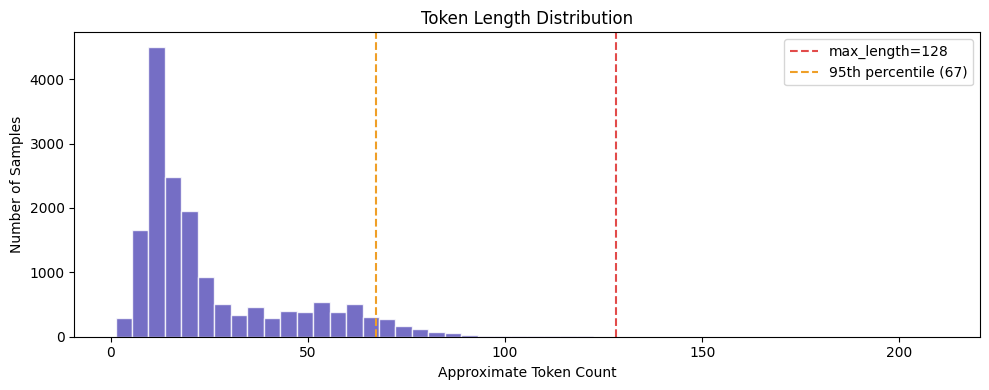

✓ Saved to figures/token_length_dist.png


In [9]:
import matplotlib.pyplot as plt

# Approximate token count — BERT adds ~20% more tokens than words
# due to subword tokenization, so we multiply by 1.2 as a safe estimate
combined_df["approx_tokens"] = combined_df["text"].apply(lambda x: len(x.split()) * 1.2)

p95 = combined_df["approx_tokens"].quantile(0.95)
p99 = combined_df["approx_tokens"].quantile(0.99)

print(f"Mean   : {combined_df['approx_tokens'].mean():.1f} tokens")
print(f"Median : {combined_df['approx_tokens'].median():.1f} tokens")
print(f"95th % : {p95:.1f} tokens")
print(f"99th % : {p99:.1f} tokens")
print(f"Max    : {combined_df['approx_tokens'].max():.1f} tokens")
print(f"\n→ max_length=128 covers {(combined_df['approx_tokens'] <= 128).mean()*100:.1f}% of samples")

plt.figure(figsize=(10, 4))
plt.hist(combined_df["approx_tokens"], bins=50, color="#534AB7", alpha=0.8, edgecolor="white")
plt.axvline(x=128, color="#E24B4A", linestyle="--", linewidth=1.5, label="max_length=128")
plt.axvline(x=p95, color="#EF9F27", linestyle="--", linewidth=1.5, label=f"95th percentile ({p95:.0f})")
plt.xlabel("Approximate Token Count")
plt.ylabel("Number of Samples")
plt.title("Token Length Distribution")
plt.legend()
plt.tight_layout()
plt.savefig("figures/token_length_dist.png", dpi=150)
plt.show()
print("✓ Saved to figures/token_length_dist.png")

## # Cell 8 — Build Train / Val / Test Splits

We split our data into three sets:
- **Train** — what the model learns from
- **Val** — used during training to monitor performance and stop early
- **Test** — touched only once at the very end to report final results

We use stratified splitting which ensures each split has the same
class ratio as the full dataset — important given our class imbalance.

We create splits for both FPB-only and combined so we can compare them in T2.

In [10]:
from sklearn.model_selection import train_test_split

def make_splits(df):
    # First split off 15% as test set
    train_val, test = train_test_split(
        df, test_size=0.15, random_state=SEED, stratify=df["label"]
    )
    # Then split remaining into 85% train, 15% val
    train, val = train_test_split(
        train_val, test_size=0.15, random_state=SEED, stratify=train_val["label"]
    )
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

# FPB only splits
fpb_train, fpb_val, fpb_test = make_splits(fpb_df)

# Combined splits
comb_train, comb_val, comb_test = make_splits(combined_df)

print("── FPB Only ──────────────────────────────")
print(f"  Train : {len(fpb_train):,}")
print(f"  Val   : {len(fpb_val):,}")
print(f"  Test  : {len(fpb_test):,}")

print("\n── Combined (FPB + Twitter) ──────────────")
print(f"  Train : {len(comb_train):,}")
print(f"  Val   : {len(comb_val):,}")
print(f"  Test  : {len(comb_test):,}")

print("\n── Class distribution (FPB train) ────────")
print(fpb_train["label_name"].value_counts().to_string())

print("\n── Class distribution (Combined train) ───")
print(comb_train["label_name"].value_counts().to_string())

── FPB Only ──────────────────────────────
  Train : 3,501
  Val   : 618
  Test  : 727

── Combined (FPB + Twitter) ──────────────
  Train : 12,095
  Val   : 2,135
  Test  : 2,512

── Class distribution (FPB train) ────────
label_name
neutral     2080
positive     985
negative     436

── Class distribution (Combined train) ───
label_name
neutral     7649
positive    2717
negative    1729


## # Cell 9 — Compute Class Weights

Because our dataset is imbalanced (neutral dominates, negative is rare),
a naive model will just predict neutral most of the time and still get
decent accuracy. Class weights fix this by penalizing the model more
when it gets a minority class wrong.

Formula: weight_i = total_samples / (n_classes × count_i)

This means rare classes get a higher weight → the model pays more
attention to them during training. We pass these weights directly
to PyTorch's CrossEntropyLoss in T2.

In [11]:
from collections import Counter

def compute_class_weights(train_df):
    counts = Counter(train_df["label"].tolist())
    total  = sum(counts.values())
    n_cls  = len(counts)
    # Higher weight for rarer classes
    weights = {
        label: total / (n_cls * count)
        for label, count in counts.items()
    }
    # Return as ordered list [w0, w1, w2] for direct use in PyTorch
    return [weights[i] for i in range(n_cls)]

fpb_weights  = compute_class_weights(fpb_train)
comb_weights = compute_class_weights(comb_train)

print("── FPB Only Weights ──────────────────────")
for i, w in enumerate(fpb_weights):
    print(f"  {ID2LABEL[i]:10s} (label {i}): {w:.4f}")

print("\n── Combined Weights ──────────────────────")
for i, w in enumerate(comb_weights):
    print(f"  {ID2LABEL[i]:10s} (label {i}): {w:.4f}")

print("\n→ Pass to PyTorch as:")
print(f"  torch.tensor({[round(w,4) for w in fpb_weights]})  # FPB only")
print(f"  torch.tensor({[round(w,4) for w in comb_weights]})  # Combined")

── FPB Only Weights ──────────────────────
  negative   (label 0): 2.6766
  neutral    (label 1): 0.5611
  positive   (label 2): 1.1848

── Combined Weights ──────────────────────
  negative   (label 0): 2.3318
  neutral    (label 1): 0.5271
  positive   (label 2): 1.4839

→ Pass to PyTorch as:
  torch.tensor([2.6766, 0.5611, 1.1848])  # FPB only
  torch.tensor([2.3318, 0.5271, 1.4839])  # Combined


## # Cell 10 — Save All Dataset Splits

We save all DataFrames and metadata to Google Drive so nothing is
lost if the Colab session disconnects. T2 will load directly from
these files without needing to re-run this notebook.

Files saved:
- fpb_train/val/test.csv        — FPB only splits
- comb_train/val/test.csv       — Combined splits  
- class_weights.json            — weights for CrossEntropyLoss
- dataset_stats.json            — stats for the report

In [ ]:
import json


SAVE_DIR = str(DATA_DIR)
os.makedirs(SAVE_DIR, exist_ok=True)

# Save all splits
fpb_train.to_csv(f"{SAVE_DIR}/fpb_train.csv",   index=False)
fpb_val.to_csv(  f"{SAVE_DIR}/fpb_val.csv",     index=False)
fpb_test.to_csv( f"{SAVE_DIR}/fpb_test.csv",    index=False)

comb_train.to_csv(f"{SAVE_DIR}/comb_train.csv", index=False)
comb_val.to_csv(  f"{SAVE_DIR}/comb_val.csv",   index=False)
comb_test.to_csv( f"{SAVE_DIR}/comb_test.csv",  index=False)

# Save weights and stats
with open(f"{SAVE_DIR}/class_weights.json", "w") as f:
    json.dump({
        "fpb_weights" : fpb_weights,
        "comb_weights": comb_weights,
        "label2id"    : LABEL2ID,
        "id2label"    : ID2LABEL
    }, f, indent=2)

with open(f"{SAVE_DIR}/dataset_stats.json", "w") as f:
    json.dump({
        "fpb_train" : len(fpb_train),  "fpb_val" : len(fpb_val),  "fpb_test" : len(fpb_test),
        "comb_train": len(comb_train), "comb_val": len(comb_val), "comb_test": len(comb_test),
        "fpb_class_dist" : fpb_train["label_name"].value_counts().to_dict(),
        "comb_class_dist": comb_train["label_name"].value_counts().to_dict(),
        "max_length"     : 128,
        "seed"           : SEED
    }, f, indent=2)

print("✓ All files saved locally")
print(f"\n  {SAVE_DIR}/")
print("  ├── fpb_train.csv")
print("  ├── fpb_val.csv")
print("  ├── fpb_test.csv")
print("  ├── comb_train.csv")
print("  ├── comb_val.csv")
print("  ├── comb_test.csv")
print("  ├── class_weights.json")
print("  └── dataset_stats.json")

## # Cell 11 — Visualization

We plot three charts to understand our data before training.
These figures will go directly into the report and presentation.

- **Chart 1** — Class distribution across all splits (shows the imbalance clearly)
- **Chart 2** — Class weights (shows how we compensate for the imbalance)
- **Chart 3** — Data source breakdown in the combined training set

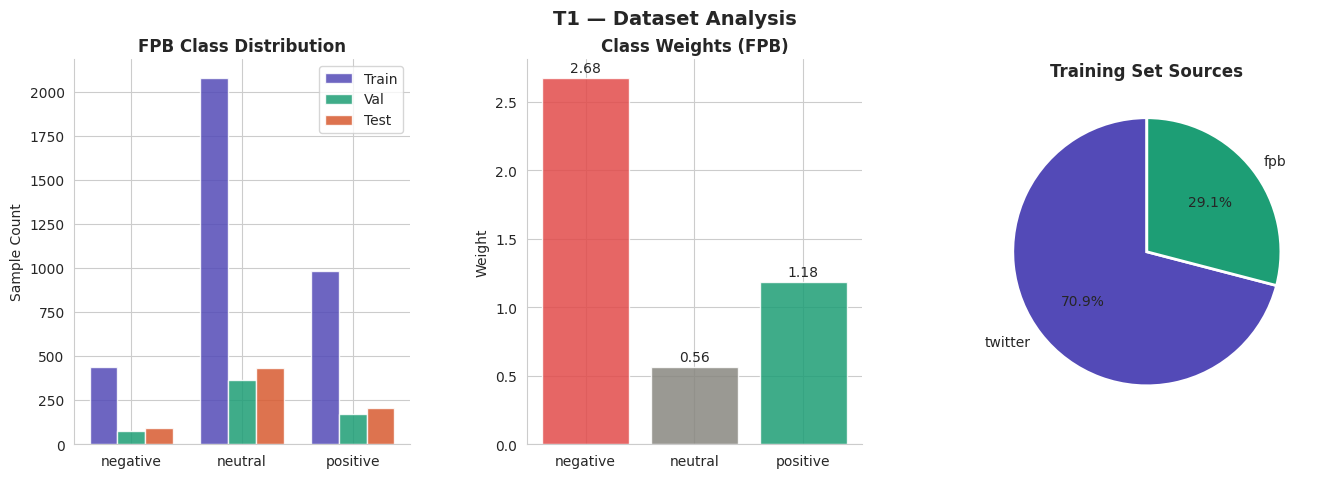

✓ Saved to figures/t1_dataset_analysis.png


In [13]:
import matplotlib.gridspec as gridspec
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

fig = plt.figure(figsize=(16, 5))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)

COLORS = [LABEL_COLORS["negative"], LABEL_COLORS["neutral"], LABEL_COLORS["positive"]]
labels = ["negative", "neutral", "positive"]

# ── Chart 1: Class distribution across splits ──────────────────
ax1 = fig.add_subplot(gs[0, 0])
x = np.arange(len(labels))
w = 0.25
train_counts = [fpb_train["label_name"].value_counts().get(l, 0) for l in labels]
val_counts   = [fpb_val["label_name"].value_counts().get(l, 0)   for l in labels]
test_counts  = [fpb_test["label_name"].value_counts().get(l, 0)  for l in labels]

ax1.bar(x - w, train_counts, w, label="Train", color="#534AB7", alpha=0.85)
ax1.bar(x,     val_counts,   w, label="Val",   color="#1D9E75", alpha=0.85)
ax1.bar(x + w, test_counts,  w, label="Test",  color="#D85A30", alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_title("FPB Class Distribution", fontweight="bold")
ax1.set_ylabel("Sample Count")
ax1.legend()

# ── Chart 2: Class weights ─────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
bars = ax2.bar(labels, fpb_weights, color=COLORS, alpha=0.85, edgecolor="white")
ax2.set_title("Class Weights (FPB)", fontweight="bold")
ax2.set_ylabel("Weight")
for bar, val in zip(bars, fpb_weights):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f"{val:.2f}", ha="center", va="bottom", fontsize=10)

# ── Chart 3: Source breakdown in combined training set ─────────
ax3 = fig.add_subplot(gs[0, 2])
source_counts = comb_train["source"].value_counts()
ax3.pie(
    source_counts.values,
    labels=source_counts.index,
    autopct="%1.1f%%",
    colors=["#534AB7", "#1D9E75"],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
ax3.set_title("Training Set Sources", fontweight="bold")

fig.suptitle("T1 — Dataset Analysis", fontsize=14, fontweight="bold")
plt.savefig("figures/t1_dataset_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved to figures/t1_dataset_analysis.png")

## # Cell 12 — Sanity Check
# New Section
Final check before we move to training. We print one sample from
each class across all splits to visually confirm:
- Labels are correctly assigned
- Text is clean
- Both sources (FPB and Twitter) are represented

If everything looks right here, T1 is complete and we are ready for T2.

In [14]:
print("=" * 60)
print("SANITY CHECK — Sample rows per class")
print("=" * 60)

for split_name, df in [("FPB TRAIN", fpb_train), ("FPB VAL", fpb_val),
                        ("FPB TEST", fpb_test), ("COMBINED TRAIN", comb_train)]:
    print(f"\n── {split_name} ──")
    for lbl in ["negative", "neutral", "positive"]:
        row = df[df["label_name"] == lbl].iloc[0]
        print(f"  [{lbl:8s}] {row['text'][:80]}...")

print("\n" + "=" * 60)
print("T1 COMPLETE ✓")
print("=" * 60)
print(f"""
Ready for T2:
  fpb_train  : {len(fpb_train):,} samples  →  FPB only training
  comb_train : {len(comb_train):,} samples  →  Combined training
  max_length : 128
  fpb_weights : {[round(w, 4) for w in fpb_weights]}
  comb_weights: {[round(w, 4) for w in comb_weights]}
""")

SANITY CHECK — Sample rows per class

── FPB TRAIN ──
  [negative] Amidst discussions on financial security, F-Secure highlights the vulnerability ...
  [neutral ] Amidst the dynamic landscape of technology, the company is poised to capitalize ...
  [positive] "The investment firm, Sunrise Valley, led by director Andrius Bagdonas, is commi...

── FPB VAL ──
  [negative] Amid financial challenges, Finnish M-real 's Kyro mill has initiated discussions...
  [neutral ] In a move that reflects Tectia Oyj's strategic vision for growth, the Finnish pr...
  [positive] "Amidst improving market conditions, the company's profitability surged, with th...

── FPB TEST ──
  [negative] Amidst prevailing economic challenges, the company reaffirmed its projection of ...
  [neutral ] "Despite recent market challenges, Quality chargers under the CHARGZ brand conti...
  [positive] In a groundbreaking achievement, both the net sales and operating profit reached...

── COMBINED TRAIN ──
  [negative] March W

## # Cell 13 — Load Data

We verify all T1 outputs are saved correctly before starting training.


In [ ]:
import os

base_path = str(DATA_DIR)

expected_files = [
    "fpb_train.csv",
    "fpb_val.csv",
    "fpb_test.csv",
    "comb_train.csv",
    "comb_val.csv",
    "comb_test.csv",
    "class_weights.json",
    "dataset_stats.json"
]

for file in expected_files:
    path = os.path.join(base_path, file)
    print(file, "✅ Found" if os.path.exists(path) else "❌ Missing")

## T2 — Fine-Tune FinBERT

## # Cell 14 — Install Required Libraries

Install the main libraries needed for model training and evaluation.

In [16]:
# Dependencies are installed using requirements.txt (see README.md).

## # Cell 15 — Load FinBERT

Load the pre-trained FinBERT model and its tokenizer.

Prepare the model so we can start fine-tuning.

In [17]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

print("✅ FinBERT loaded successfully")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ FinBERT loaded successfully


## # Cell **16** — Load Dataset

Load the training and validation data from the project folder.

In [ ]:
import pandas as pd

base_path = str(DATA_DIR)

fpb_train = pd.read_csv(f"{base_path}/fpb_train.csv")
fpb_val = pd.read_csv(f"{base_path}/fpb_val.csv")

print("Train size:", len(fpb_train))
print("Validation size:", len(fpb_val))

fpb_train.head()

## # Cell **17** — Tokenization

Convert text into tokens that the model can understand.


In [19]:
def tokenize_data(df):
    return tokenizer(
        df["text"].tolist(),
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

train_encodings = tokenize_data(fpb_train)
val_encodings = tokenize_data(fpb_val)

print("✅ Tokenization done")

✅ Tokenization done


## # Cell **18** — Create Dataset

Combine tokens + labels into a format ready for training.


In [20]:
import torch

class FinDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)


train_dataset = FinDataset(train_encodings, fpb_train["label"].tolist())
val_dataset = FinDataset(val_encodings, fpb_val["label"].tolist())

print("✅ Dataset ready")

✅ Dataset ready


## # Cell **19** — Training Setup

Set the training settings for fine-tuning FinBERT.


In [21]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=str(MODELS_DIR / "finbert_fpb"),
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_dir=str(LOGS_DIR / "finbert"),
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=50
)

print("✅ Training arguments ready")

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


✅ Training arguments ready


## # Cell **20** — Start Training

Start fine-tuning the FinBERT model using our dataset.


In [22]:
from transformers import Trainer
import json
import torch

with open(f"{base_path}/class_weights.json") as f:
    weights_data = json.load(f)
fpb_weights = weights_data["fpb_weights"]

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        w = torch.tensor(fpb_weights).float().to(logits.device)
        loss = torch.nn.CrossEntropyLoss(weight=w)(logits, labels)
        return (loss, outputs) if return_outputs else loss

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset
)

trainer.train()

Epoch,Training Loss,Validation Loss
1,0.461666,0.397547
2,0.340742,0.371434
3,0.205060,0.381145


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

TrainOutput(global_step=657, training_loss=0.4417213116243731, metrics={'train_runtime': 389.8466, 'train_samples_per_second': 26.941, 'train_steps_per_second': 1.685, 'total_flos': 690870056599296.0, 'train_loss': 0.4417213116243731, 'epoch': 3.0})

## # Cell **21** — Save Fine-Tuned FinBERT

Save the best trained model and tokenizer in the project folder.


In [23]:
save_path = str(MODELS_DIR / "finbert_fpb_best")

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print("✅ Fine-tuned FinBERT saved successfully")
print("Saved to:", save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Fine-tuned FinBERT saved successfully
Saved to: /content/CPCS432_Project/models/finbert_fpb_best


## # Cell **22** — Evaluate Model

Evaluate the model on test data using accuracy and F1 score.


In [24]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Load test data
fpb_test = pd.read_csv(f"{base_path}/fpb_test.csv")

# Tokenize test data
test_encodings = tokenize_data(fpb_test)

# Create dataset
test_dataset = FinDataset(test_encodings, fpb_test["label"].tolist())

# Predictions
predictions = trainer.predict(test_dataset)
preds = predictions.predictions.argmax(axis=1)
labels = predictions.label_ids

# Metrics
accuracy   = accuracy_score(labels, preds)
f1_weighted = f1_score(labels, preds, average="weighted")
f1_macro    = f1_score(labels, preds, average="macro")


finbert_acc = accuracy
finbert_f1w = f1_weighted
finbert_f1m = f1_macro

print(f"Accuracy        : {accuracy:.4f}")
print(f"Weighted F1     : {f1_weighted:.4f}")
print(f"Macro F1        : {f1_macro:.4f}")
print("\nPer-class report:")
print(classification_report(labels, preds, target_names=["Negative", "Neutral", "Positive"]))

Accuracy        : 0.8184
Weighted F1     : 0.8192
Macro F1        : 0.8132

Per-class report:
              precision    recall  f1-score   support

    Negative       0.77      0.92      0.84        91
     Neutral       0.88      0.82      0.85       432
    Positive       0.73      0.77      0.75       204

    accuracy                           0.82       727
   macro avg       0.79      0.84      0.81       727
weighted avg       0.82      0.82      0.82       727



## # Cell **23** — Confusion Matrix


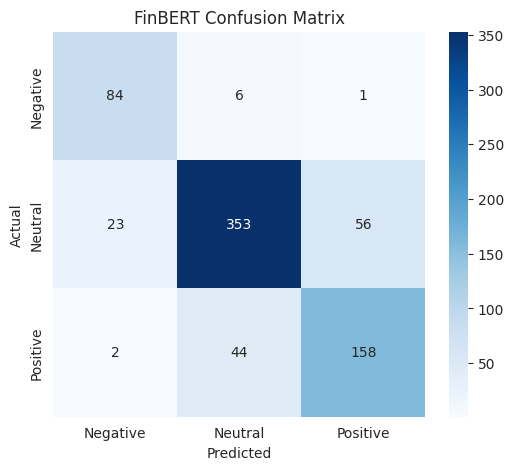

In [25]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(labels, preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Neutral", "Positive"],
            yticklabels=["Negative", "Neutral", "Positive"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("FinBERT Confusion Matrix")
plt.show()

## T3 — Fine-tune BERT (Baseline)

## # Cell **24** — Load BERT

Load the standard BERT model for comparison.


In [26]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "bert-base-uncased"

tokenizer_bert = AutoTokenizer.from_pretrained(model_name)
model_bert = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

print("✅ BERT loaded successfully")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ BERT loaded successfully


## # Cell **25** — Tokenize Data for BERT

Convert the same FPB data using BERT’s tokenizer.


In [27]:
def tokenize_data_bert(df):
    return tokenizer_bert(
        df["text"].tolist(),
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

bert_train_encodings = tokenize_data_bert(fpb_train)
bert_val_encodings = tokenize_data_bert(fpb_val)

bert_train_dataset = FinDataset(bert_train_encodings, fpb_train["label"].tolist())
bert_val_dataset = FinDataset(bert_val_encodings, fpb_val["label"].tolist())

print("✅ BERT datasets ready")

✅ BERT datasets ready


## # Cell **26** — Training Setup (BERT)

Use the same training settings for fair comparison.


In [28]:
from transformers import TrainingArguments

training_args_bert = TrainingArguments(
    output_dir=str(MODELS_DIR / "bert_fpb"),
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_dir=str(LOGS_DIR / "bert"),
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=50
)

print("✅ BERT training args ready")

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


✅ BERT training args ready


## # Cell **27** — Train BERT

Start fine-tuning the standard BERT model.


In [29]:
from transformers import Trainer

bert_trainer = Trainer(
    model=model_bert,
    args=training_args_bert,
    train_dataset=bert_train_dataset,
    eval_dataset=bert_val_dataset
)

bert_trainer.train()

Epoch,Training Loss,Validation Loss
1,0.465966,0.453812
2,0.362458,0.390137
3,0.256280,0.433890


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

TrainOutput(global_step=657, training_loss=0.4063875624396848, metrics={'train_runtime': 430.1304, 'train_samples_per_second': 24.418, 'train_steps_per_second': 1.527, 'total_flos': 690870056599296.0, 'train_loss': 0.4063875624396848, 'epoch': 3.0})

 ### Cell **28** — Save Fine-Tuned BERT
Save the best trained model and tokenizer in the project folder.

In [30]:
bert_save_path = str(MODELS_DIR / "bert_fpb_best")

bert_trainer.save_model(bert_save_path)
tokenizer_bert.save_pretrained(bert_save_path)

print("✅ Fine-tuned BERT saved successfully")
print("Saved to:", bert_save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Fine-tuned BERT saved successfully
Saved to: /content/CPCS432_Project/models/bert_fpb_best


## # Cell **29** — Evaluate BERT (Accuracy + F1)


In [31]:
# Load test data
fpb_test = pd.read_csv(f"{base_path}/fpb_test.csv")

# Tokenize
bert_test_encodings = tokenize_data_bert(fpb_test)

# Dataset
bert_test_dataset = FinDataset(bert_test_encodings, fpb_test["label"].tolist())

# Predictions
predictions = bert_trainer.predict(bert_test_dataset)
preds = predictions.predictions.argmax(axis=1)
labels = predictions.label_ids

# Metrics
accuracy    = accuracy_score(labels, preds)
f1_weighted = f1_score(labels, preds, average="weighted")
f1_macro    = f1_score(labels, preds, average="macro")

bert_acc = accuracy
bert_f1w = f1_weighted
bert_f1m = f1_macro

print(f"BERT Accuracy        : {accuracy:.4f}")
print(f"BERT Weighted F1     : {f1_weighted:.4f}")
print(f"BERT Macro F1        : {f1_macro:.4f}")
print("\nPer-class report:")
print(classification_report(labels, preds, target_names=["Negative", "Neutral", "Positive"]))

BERT Accuracy        : 0.8088
BERT Weighted F1     : 0.8067
BERT Macro F1        : 0.7997

Per-class report:
              precision    recall  f1-score   support

    Negative       0.80      0.89      0.84        91
     Neutral       0.83      0.86      0.84       432
    Positive       0.76      0.67      0.71       204

    accuracy                           0.81       727
   macro avg       0.80      0.81      0.80       727
weighted avg       0.81      0.81      0.81       727



## # Cell **30** — Confusion Matrix (BERT)

Visualize BERT predictions to compare with FinBERT.


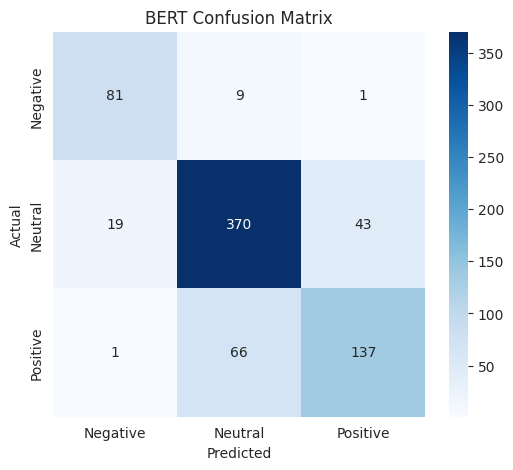

In [32]:
from sklearn.metrics import confusion_matrix

cm_bert = confusion_matrix(labels, preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm_bert, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Neutral", "Positive"],
            yticklabels=["Negative", "Neutral", "Positive"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BERT Confusion Matrix")
plt.show()

## T4 — TF-IDF + Logistic Regression

## # Cell **31** — TF-IDF + Logistic Regression

Convert text into TF-IDF features and train a simple classifier.


In [33]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Vectorize text
vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(fpb_train["text"])
X_test = vectorizer.transform(fpb_test["text"])

y_train = fpb_train["label"]
y_test = fpb_test["label"]

# Train model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

print("✅ Logistic Regression trained")

✅ Logistic Regression trained


## # Cell **32** — Evaluate Logistic Regression

Measure accuracy and F1 score.


In [35]:
from sklearn.metrics import accuracy_score, f1_score

# Predictions
lr_preds = lr_model.predict(X_test)

# Metrics
accuracy   = accuracy_score(labels, preds)
f1_weighted = f1_score(labels, preds, average="weighted")
f1_macro    = f1_score(labels, preds, average="macro")


tfidf_acc = accuracy
tfidf_f1w = f1_weighted
tfidf_f1m = f1_macro

print("LR Accuracy:", tfidf_acc)
print("LR F1 wiehgted:", tfidf_f1w)
print("LR F1 macro Score:", tfidf_f1m)

LR Accuracy: 0.8088033012379643
LR F1 wiehgted: 0.8067139738252552
LR F1 macro Score: 0.7997413148425121


## # Cell **33** — Confusion Matrix (Logistic Regression)

Visualize errors for the baseline model.


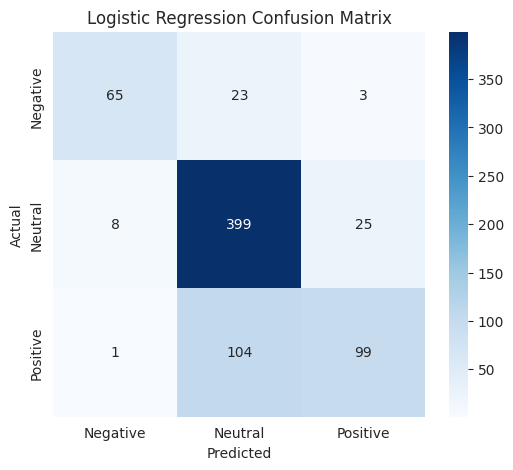

In [36]:
from sklearn.metrics import confusion_matrix

cm_lr = confusion_matrix(y_test, lr_preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Neutral", "Positive"],
            yticklabels=["Negative", "Neutral", "Positive"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## T5 — Evaluate all three — F1, accuracy, confusion matrix


## # Cell **34** — Classification Reports

Generate detailed precision, recall, and F1 for each class.


In [37]:
bert_predictions = bert_trainer.predict(bert_test_dataset)
bert_preds = bert_predictions.predictions.argmax(axis=1)

## # Cell 33b — Model Comparison Summary

Side-by-side comparison of all three models. This is the key evaluation
table that goes directly into the report.



In [38]:
import pandas as pd

comparison = pd.DataFrame([
    {"Model": "FinBERT (FPB only)",  "Accuracy": finbert_acc,  "Weighted F1": finbert_f1w,  "Macro F1": finbert_f1m},
    {"Model": "BERT (FPB only)",     "Accuracy": bert_acc,     "Weighted F1": bert_f1w,     "Macro F1": bert_f1m},
    {"Model": "TF-IDF + LR",         "Accuracy": tfidf_acc,    "Weighted F1": tfidf_f1w,    "Macro F1": tfidf_f1m},
])

print(comparison.to_string(index=False))

             Model  Accuracy  Weighted F1  Macro F1
FinBERT (FPB only)  0.818432     0.819191  0.813229
   BERT (FPB only)  0.808803     0.806714  0.799741
       TF-IDF + LR  0.808803     0.806714  0.799741


In [39]:
from sklearn.metrics import classification_report

target_names = ["Negative", "Neutral", "Positive"]

print("===== FinBERT Classification Report =====")
print(classification_report(labels, preds, target_names=target_names))

print("===== BERT Classification Report =====")
print(classification_report(labels, bert_preds, target_names=target_names))

print("===== Logistic Regression Classification Report =====")
print(classification_report(y_test, lr_preds, target_names=target_names))

===== FinBERT Classification Report =====
              precision    recall  f1-score   support

    Negative       0.80      0.89      0.84        91
     Neutral       0.83      0.86      0.84       432
    Positive       0.76      0.67      0.71       204

    accuracy                           0.81       727
   macro avg       0.80      0.81      0.80       727
weighted avg       0.81      0.81      0.81       727

===== BERT Classification Report =====
              precision    recall  f1-score   support

    Negative       0.80      0.89      0.84        91
     Neutral       0.83      0.86      0.84       432
    Positive       0.76      0.67      0.71       204

    accuracy                           0.81       727
   macro avg       0.80      0.81      0.80       727
weighted avg       0.81      0.81      0.81       727

===== Logistic Regression Classification Report =====
              precision    recall  f1-score   support

    Negative       0.88      0.71      0.79     

## T6 — Attention map visualization (BertViz)



## # Cell **35** — Install BertViz


In [40]:
# Dependencies are installed using requirements.txt (see README.md).

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.5/140.5 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 74.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 10.4 MB/s eta 0:00:00


## # Cell **36** — Load Saved FinBERT for Attention

Load the saved FinBERT model with attention outputs enabled.


In [41]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

attention_model_path = str(MODELS_DIR / "finbert_fpb_best")

attention_tokenizer = AutoTokenizer.from_pretrained(attention_model_path)
attention_model = AutoModelForSequenceClassification.from_pretrained(
    attention_model_path,
    output_attentions=True
)

print("✅ FinBERT loaded with attention enabled")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ FinBERT loaded with attention enabled


## # Cell **37** — Visualize Attention (BertViz)

Show which words FinBERT focuses on.


In [42]:
from bertviz import head_view
import torch

def visualize_attention(text):
    inputs = attention_tokenizer(text, return_tensors="pt")

    with torch.no_grad():
        outputs = attention_model(**inputs)

    attention = outputs.attentions
    tokens = attention_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    head_view(attention, tokens)

# Example
#Positive
visualize_attention("The company reported strong profit growth this quarter.")
#Negative
visualize_attention("The company suffered heavy losses due to declining revenue.")
#Neutral
visualize_attention("The company announced its quarterly earnings report.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## # Cell **38** — Load Combined Dataset

Load the combined dataset that includes both FinancialPhraseBank and Twitter financial sentiment data.

In [ ]:
import pandas as pd

base_path = str(DATA_DIR)

comb_train = pd.read_csv(f"{base_path}/comb_train.csv")
comb_val = pd.read_csv(f"{base_path}/comb_val.csv")
comb_test = pd.read_csv(f"{base_path}/comb_test.csv")

print("Combined Train size:", len(comb_train))
print("Combined Validation size:", len(comb_val))
print("Combined Test size:", len(comb_test))

comb_train.head()


## # Cell **39** — Load Fresh FinBERT

Load a fresh FinBERT model before training on the combined dataset.

In [44]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "ProsusAI/finbert"

tokenizer_comb = AutoTokenizer.from_pretrained(model_name)

model_comb = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3
)

print("✅ Fresh FinBERT loaded for combined training")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Fresh FinBERT loaded for combined training


## # Cell **40** — Tokenize Combined Dataset

Convert the combined text data into tokens that FinBERT can understand.

In [45]:
def tokenize_combined(df):
    return tokenizer_comb(
        df["text"].tolist(),
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    )

comb_train_encodings = tokenize_combined(comb_train)
comb_val_encodings = tokenize_combined(comb_val)
comb_test_encodings = tokenize_combined(comb_test)

print("✅ Combined dataset tokenized")

✅ Combined dataset tokenized


## # Cell **41** — Create Combined Dataset

Create PyTorch datasets for training, validation, and testing.

In [46]:
comb_train_dataset = FinDataset(
    comb_train_encodings,
    comb_train["label"].tolist()
)

comb_val_dataset = FinDataset(
    comb_val_encodings,
    comb_val["label"].tolist()
)

comb_test_dataset = FinDataset(
    comb_test_encodings,
    comb_test["label"].tolist()
)

print("✅ Combined datasets created")

✅ Combined datasets created


## # Cell **42** — Training Arguments for Combined FinBERT

Set the training configuration for FinBERT using the combined dataset.

In [47]:
from transformers import TrainingArguments

training_args_comb = TrainingArguments(
    output_dir=str(MODELS_DIR / "finbert_combined"),

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    logging_steps=50,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=3,

    weight_decay=0.01,

    logging_dir=str(LOGS_DIR / "combined"),

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss"
)

print("✅ Combined training arguments ready")

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


✅ Combined training arguments ready


## # Cell **43** — Train FinBERT on Combined Dataset

Fine-tune FinBERT using the combined FPB + Twitter dataset.

In [48]:
class WeightedTrainerComb(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        w = torch.tensor(comb_weights).float().to(logits.device)
        loss = torch.nn.CrossEntropyLoss(weight=w)(logits, labels)
        return (loss, outputs) if return_outputs else loss

trainer_comb = WeightedTrainerComb(
    model=model_comb,
    args=training_args_comb,
    train_dataset=comb_train_dataset,
    eval_dataset=comb_val_dataset
)

trainer_comb.train()

Epoch,Training Loss,Validation Loss
1,0.482675,0.401064
2,0.287133,0.443164
3,0.134090,0.494265


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

TrainOutput(global_step=2268, training_loss=0.3492129417744053, metrics={'train_runtime': 994.4928, 'train_samples_per_second': 36.486, 'train_steps_per_second': 2.281, 'total_flos': 2386767590565120.0, 'train_loss': 0.3492129417744053, 'epoch': 3.0})

## # Cell **44** — Save Combined FinBERT

Save the fine-tuned FinBERT model trained on FPB + Twitter data.

In [49]:
comb_save_path = str(MODELS_DIR / "finbert_combined_best")

trainer_comb.save_model(comb_save_path)
tokenizer_comb.save_pretrained(comb_save_path)

print("✅ Combined FinBERT saved successfully")
print("Saved to:", comb_save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Combined FinBERT saved successfully
Saved to: /content/CPCS432_Project/models/finbert_combined_best


## # Cell **45** — Evaluate Combined FinBERT

Evaluate the FinBERT model trained on FPB + Twitter data.

In [50]:
from sklearn.metrics import accuracy_score, f1_score

# Predictions
comb_predictions = trainer_comb.predict(comb_test_dataset)

comb_preds = comb_predictions.predictions.argmax(axis=-1)
comb_labels = comb_predictions.label_ids

# Metrics
comb_accuracy = accuracy_score(comb_labels, comb_preds)

comb_f1 = f1_score(
    comb_labels,
    comb_preds,
    average="weighted"
)

print("Combined FinBERT Accuracy:", comb_accuracy)
print("Combined FinBERT F1 Score:", comb_f1)

Combined FinBERT Accuracy: 0.8343949044585988
Combined FinBERT F1 Score: 0.8374877143736188


## # Cell **46** — Combined FinBERT Confusion Matrix

Visualize prediction performance for the combined model.

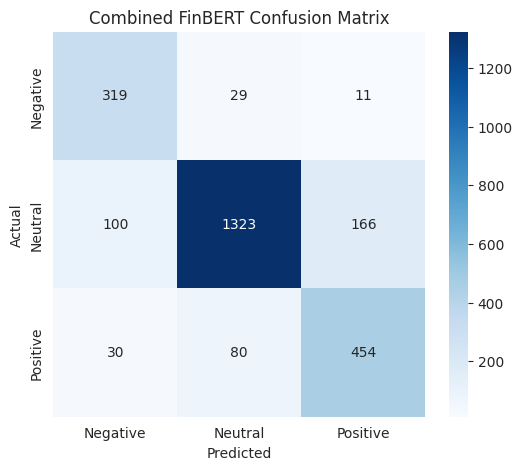

In [51]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_comb = confusion_matrix(comb_labels, comb_preds)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_comb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Combined FinBERT Confusion Matrix")

plt.show()

## # Cell **47** — Final Comparison Table

Compare FinBERT performance before and after adding Twitter data.

In [52]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Training Data": [
        "FPB Only",
        "FPB + Twitter"
    ],

    "Accuracy": [
        0.83,
        round(comb_accuracy, 4)
    ],

    "F1 Score": [
        0.81,
        round(comb_f1, 4)
    ]
})

comparison_df

,Training Data,Accuracy,F1 Score
0,FPB Only,0.8300,0.8100
1,FPB + Twitter,0.8344,0.8375


## # Cell **48** — Classification Report for Combined FinBERT

Generate detailed precision, recall, and F1 scores for each class.

In [53]:
from sklearn.metrics import classification_report

target_names = ["Negative", "Neutral", "Positive"]

print("===== Combined FinBERT Classification Report =====")

print(
    classification_report(
        comb_labels,
        comb_preds,
        target_names=target_names
    )
)

===== Combined FinBERT Classification Report =====
              precision    recall  f1-score   support

    Negative       0.71      0.89      0.79       359
     Neutral       0.92      0.83      0.88      1589
    Positive       0.72      0.80      0.76       564

    accuracy                           0.83      2512
   macro avg       0.78      0.84      0.81      2512
weighted avg       0.85      0.83      0.84      2512



## # Cell **49** — Sentiment-Based Price Direction Predictor

## # What this is

We now connect FinBERT's sentiment outputs to actual market movements.

For each article in our test set, we extract three values from FinBERT's
softmax output: the probability of being negative, neutral, or positive.
These become features for a simple logistic regression that tries to predict
whether the stock moved **up** or **down** the next day.

This is the second stage of our sentiment-to-signal pipeline:

    Text → FinBERT → [P(neg), P(neu), P(pos)] → Logistic Regression → {UP, DOWN}

We call it an **experimental indicator** because the dataset is small and
financial price movement is noisy. The goal here is to demonstrate the
pipeline architecture and show whether sentiment signal is at all detectable —
not to build a production trading system.

**Why logistic regression?**  
It's interpretable. We can read the coefficients directly to understand
whether positive sentiment correlates with upward movement, as expect

In [54]:
import os
import json
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

print("✅ Libraries ready")

✅ Libraries ready


## # Cell **50** — Load Saved FinBERT + Test Set

We load the fine-tuned FinBERT we saved in T2, along with the FPB test set.
We use the same local path from T2 so everything stays consistent —
no retraining needed here.

In [55]:
base_path  = str(DATA_DIR)
model_path = str(MODELS_DIR / "finbert_fpb_best")

# Load fine-tuned FinBERT
tokenizer_t7 = AutoTokenizer.from_pretrained(model_path)
model_t7     = AutoModelForSequenceClassification.from_pretrained(model_path)
model_t7.eval()

# Load test set
fpb_test = pd.read_csv(f"{base_path}/fpb_test.csv")

print(f"✅ FinBERT loaded from: {model_path}")
print(f"✅ Test set loaded: {len(fpb_test):,} samples")
print(fpb_test[["text", "label"]].head(3))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ FinBERT loaded from: /content/CPCS432_Project/models/finbert_fpb_best
✅ Test set loaded: 727 samples
                                                text  label
0  "Despite recent market challenges, Quality cha...      1
1  In a groundbreaking achievement, both the net ...      2
2  Gradually reaching 2% by the end of 2010, as f...      1


## # Cell 51 — Extract Sentiment Probabilities from FinBERT

Instead of using the hard predicted label (negative / neutral / positive),
we extract the raw softmax probabilities from FinBERT's output layer.

This gives us three continuous features per sentence:
- P(negative) — how strongly the model reads this as bad news
- P(neutral)  — how strongly the model reads this as factual / flat
- P(positive) — how strongly the model reads this as good news

These three values together carry more information than a single label.
For example, a sentence with P(pos)=0.95 is a much stronger signal
than one with P(pos)=0.51 — the logistic regression in Cell 42 can
exploit this difference.

In [56]:
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

def get_sentiment_probs(texts, tokenizer, model, batch_size=32):
    all_probs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        enc   = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )
        with torch.no_grad():
            logits = model(**enc).logits
        probs = F.softmax(logits, dim=-1).cpu().numpy()
        all_probs.append(probs)
    return np.vstack(all_probs)

probs = get_sentiment_probs(fpb_test["text"].tolist(), tokenizer_t7, model_t7)

# Add columns to test DataFrame for inspection
fpb_test["p_neg"] = probs[:, 0]
fpb_test["p_neu"] = probs[:, 1]
fpb_test["p_pos"] = probs[:, 2]

print(f"✅ Probabilities extracted for {len(fpb_test):,} samples")
print(fpb_test[["text", "p_neg", "p_neu", "p_pos"]].head(5).to_string())

✅ Probabilities extracted for 727 samples
                                                                                                                                                                                                                                                                                                                                                                   text     p_neg     p_neu     p_pos
0                                                                          "Despite recent market challenges, Quality chargers under the CHARGZ brand continue to gain momentum, securing prominent shelf space in select retail stores and expanding their presence in various sales locations worldwide, reflecting growing demand and positive consumer confidence."  0.003863  0.792856  0.203281
1                                                                                                                                                                          In a gr

## # Cell 52 — News Fetcher & Article Extractor

We fetch the latest news articles for a given stock ticker using
yfinance, then extract the full article text using newspaper3k.

Key design decisions:
- Full article text is preferred over summary for richer FinBERT input
- If full article extraction fails (paywall/blocked), falls back to summary
- If summary unavailable, falls back to headline
- Date extracted directly from pubDate field
- Relevance filter: articles must mention the ticker OR company name
  to avoid loosely related articles polluting the analysis
- resolve_ticker() handles both tickers ("AAPL") and company names
  ("Apple") — rejects results that look invalid

In [57]:
import yfinance as yf
import time
from newspaper import Article

def resolve_ticker(user_input):
    """
    Resolve a ticker or company name to a valid ticker symbol.
    Returns (ticker, company_name) or (None, None) if not found.
    """
    cleaned = user_input.strip()

    # Already looks like a ticker
    if len(cleaned) <= 5 and cleaned.isalpha():
      try:
          info = yf.Ticker(cleaned.upper()).info
          name = info.get("longName", "") or info.get("shortName", "")
          return cleaned.upper(), name if name else cleaned.upper()
      except:
          return cleaned.upper(), cleaned.upper()

    # Try yfinance search
    try:
        search_results = yf.Search(cleaned).quotes
        if search_results:
            for result in search_results:
                if result.get("quoteType", "") in ["EQUITY", "ETF"]:
                    ticker = result.get("symbol", "")
                    name   = result.get("longname", "") or result.get("shortname", "")
                    # Reject if ticker looks wrong
                    if ticker and len(ticker) <= 5 and ticker != cleaned.upper():
                        return ticker, name
    except Exception as e:
        print(f"  Ticker resolution failed: {e}")

    return None, None


def fetch_full_article(url):
    """
    Attempt to fetch full article text from URL using newspaper3k.
    Returns None if blocked or failed.
    """
    try:
        article = Article(url)
        article.download()
        article.parse()
        text = article.text.strip()
        if len(text) > 100:
            return text
        return None
    except Exception:
        return None


def is_relevant(text, title, ticker, company_name):
    """
    Check if article is relevant to the searched stock.
    Relaxed filter — only removes clearly unrelated articles.
    """
    # If no company name provided skip filtering entirely
    if not company_name or company_name == ticker:
        return True

    ticker_upper = ticker.upper()
    combined     = (title + " " + text).upper()

    # Check ticker
    if ticker_upper in combined:
        return True

    # Check any meaningful word from company name (>3 chars)
    for word in company_name.split():
        if len(word) > 3 and word.upper() in combined:
            return True

    return False


def fetch_news_for_ticker(ticker, company_name="", max_articles=10):
    """
    Fetch up to max_articles relevant news articles for a given ticker.
    Returns a list of dicts with title, text, url, date.
    """
    results  = []
    filtered = 0

    try:
        news_items = yf.Ticker(ticker.upper()).news
        if not news_items:
            print(f"  No news found for {ticker}")
            return results

        for item in news_items:
            if len(results) >= max_articles:
                break

            content = item.get("content", {})
            title   = content.get("title", "")
            url     = content.get("canonicalUrl", {}).get("url", "")
            summary = content.get("summary", "") or content.get("description", "")

            # Clean date
            pub_date = content.get("pubDate", "")[:10] or "Unknown"

            # Get best available text
            full_text = fetch_full_article(url) if url else None
            text      = full_text if full_text else summary if summary else title

            if not text:
                continue

            # Relevance filter
            if not is_relevant(text, title, ticker, company_name):
                filtered += 1
                continue

            results.append({
                "title"      : title,
                "text"       : text,
                "url"        : url,
                "date"       : pub_date,
                "text_source": "full_article" if full_text else
                               "summary"      if summary   else "title"
            })
            time.sleep(0.3)

    except Exception as e:
        print(f"  Error fetching news for {ticker}: {e}")

    if filtered > 0:
        print(f"  Filtered {filtered} irrelevant articles")

    return results


print("✅ News fetcher ready")
print("   Full article extraction : newspaper3k with summary fallback")
print("   Relevance filter        : ticker OR company name must appear")
print("   Max articles per search : 10")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 109.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.1/211.1 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.5/81.5 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.9/105.9 kB 11.1 MB/s eta 0:00:00
✅ News fetcher ready
   Full article extraction : newspaper3k with summary fallback
   Relevance filter        : ticker OR company name must appear
   Max articles per search : 10


## # Cell 53 — FinBERT Inference

We now build the core sentiment scoring function.

Given any text input, this function:
1. Tokenizes it using FinBERT's WordPiece tokenizer
2. Runs it through the fine-tuned model
3. Returns the sentiment label, confidence score,
   and all three raw probabilities [P(neg), P(neu), P(pos)]

For long articles we chunk the text into overlapping windows
of 512 tokens and average the probabilities across chunks.
This way no content is lost due to FinBERT's token limit.



In [58]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load fine-tuned FinBERT (already trained in T2)
LABELS = {0: "Negative", 1: "Neutral", 2: "Positive"}

model_path   = str(MODELS_DIR / "finbert_fpb_best")
tokenizer_fi = AutoTokenizer.from_pretrained(model_path)
model_fi     = AutoModelForSequenceClassification.from_pretrained(model_path)
model_fi.eval()

def chunk_text(text, tokenizer, max_length=512, overlap=50):
    """
    Split long text into overlapping chunks of max_length tokens.
    Overlap ensures sentences at boundaries are not cut off.
    """
    tokens = tokenizer.encode(text, add_special_tokens=False)
    chunks = []
    step   = max_length - overlap - 2  # account for [CLS] and [SEP]
    for i in range(0, len(tokens), step):
        chunk = tokens[i : i + max_length - 2]
        chunks.append(chunk)
        if i + max_length - 2 >= len(tokens):
            break
    return chunks

def analyze_sentiment(text):
    """
    Run FinBERT on input text. Handles long articles via chunking.
    Returns:
        label      — Positive / Negative / Neutral
        confidence — model certainty (0-1)
        probs      — dict with all three class probabilities
    """
    if not text or len(text.strip()) < 5:
        return {"label": "Unknown", "confidence": 0.0,
                "probs": {"Negative": 0, "Neutral": 0, "Positive": 0}}

    tokens = tokenizer_fi.encode(text, add_special_tokens=False)

    if len(tokens) <= 510:
        # Short text — single pass
        enc = tokenizer_fi(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=512,
            padding=True
        )
        with torch.no_grad():
            logits = model_fi(**enc).logits
        probs = F.softmax(logits, dim=-1).squeeze().tolist()

    else:
        # Long article — chunk and average
        chunks     = chunk_text(text, tokenizer_fi)
        all_probs  = []
        for chunk in chunks:
            enc = tokenizer_fi(
                tokenizer_fi.decode(chunk),
                return_tensors="pt",
                truncation=True,
                max_length=512,
                padding=True
            )
            with torch.no_grad():
                logits = model_fi(**enc).logits
            all_probs.append(F.softmax(logits, dim=-1).squeeze().tolist())
        probs = [sum(p[i] for p in all_probs) / len(all_probs) for i in range(3)]

    label_id   = int(torch.tensor(probs).argmax())
    label      = LABELS[label_id]
    confidence = probs[label_id]

    return {
        "label"     : label,
        "confidence": round(confidence, 4),
        "probs"     : {
            "Negative": round(probs[0], 4),
            "Neutral" : round(probs[1], 4),
            "Positive": round(probs[2], 4)
        }
    }

print("✅ FinBERT inference engine ready")
print("   Chunking: enabled for articles > 510 tokens")
print("   Labels: Negative / Neutral / Positive")

# Quick test
test = analyze_sentiment("Apple reported record quarterly earnings, beating analyst expectations.")
print(f"\n── Quick test ─────────────────────────────")
print(f"   Text      : Apple reported record quarterly earnings...")
print(f"   Sentiment : {test['label']} ({test['confidence']*100:.1f}%)")
print(f"   Probs     : {test['probs']}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ FinBERT inference engine ready
   Chunking: enabled for articles > 510 tokens
   Labels: Negative / Neutral / Positive

── Quick test ─────────────────────────────
   Text      : Apple reported record quarterly earnings...
   Sentiment : Positive (82.5%)
   Probs     : {'Negative': 0.1181, 'Neutral': 0.0571, 'Positive': 0.8248}


## # Cell 54 — Event Detection & Subject Extraction

For each article we detect two things:

**1. Event Type** — what kind of financial event the article describes,
using a keyword-based classifier across 6 categories:
- Earnings    — quarterly results, revenue, EPS, guidance
- Lawsuit     — legal action, SEC, settlement, fraud
- Acquisition — merger, buyout, takeover, deal
- Downgrade   — analyst rating, price target, upgrade/downgrade
- Product     — launch, release, new product, announcement
- Macro       — Fed, interest rates, inflation, recession
- General     — fallback if no keywords match

**2. Subjects** — who or what the article is actually about,
extracted using spaCy's Named Entity Recognition (NER).
We extract three entity types:
- ORG    — companies and organizations (Apple, Goldman Sachs)
- PERSON — people (Elon Musk, Tim Cook)
- GPE    — geopolitical entities (USA, China)

This helps flag articles that mention the searched ticker
but are primarily about a different company or person.

In [59]:
EVENT_KEYWORDS = {
    "Earnings": [
        "earnings", "revenue", "profit", "loss", "EPS", "quarterly",
        "guidance", "beat", "miss", "forecast", "results", "income",
        "margin", "EBITDA", "outlook"
    ],
    "Lawsuit": [
        "lawsuit", "sued", "legal", "court", "SEC", "settlement",
        "fraud", "investigation", "penalty", "fine", "charges",
        "regulatory", "violation", "probe"
    ],
    "Acquisition": [
        "acquisition", "merger", "acquire", "buyout", "takeover",
        "deal", "purchase", "bid", "offer", "stake", "joint venture"
    ],
    "Downgrade": [
        "downgrade", "upgrade", "rating", "price target", "analyst",
        "overweight", "underweight", "buy rating", "sell rating",
        "neutral", "outperform", "underperform", "hold"
    ],
    "Product": [
        "launch", "release", "product", "announcement", "new model",
        "unveiled", "introduced", "feature", "update", "version",
        "innovation", "patent"
    ],
    "Macro": [
        "Fed", "Federal Reserve", "interest rate", "inflation",
        "recession", "GDP", "unemployment", "CPI", "monetary policy",
        "rate hike", "rate cut", "tariff", "trade war"
    ]
}

def detect_event(text):
    """
    Classify article into an event type based on keyword matching.
    Returns the event type with the most keyword hits.
    Falls back to 'General' if no keywords match.
    """
    text_lower = text.lower()
    scores     = {}

    for event, keywords in EVENT_KEYWORDS.items():
        score = sum(1 for kw in keywords if kw.lower() in text_lower)
        if score > 0:
            scores[event] = score

    if not scores:
        return "General"

    return max(scores, key=scores.get)

print("✅ Event detection ready")
print(f"   Categories: {', '.join(EVENT_KEYWORDS.keys())}, General")

# Quick test
sample = "Apple reported record quarterly earnings, beating analyst EPS expectations by 12%."
print(f"\n── Quick test ─────────────────────────────")
print(f"   Text  : {sample}")
print(f"   Event : {detect_event(sample)}")

✅ Event detection ready
   Categories: Earnings, Lawsuit, Acquisition, Downgrade, Product, Macro, General

── Quick test ─────────────────────────────
   Text  : Apple reported record quarterly earnings, beating analyst EPS expectations by 12%.
   Event : Earnings


In [60]:
!python -m spacy download en_core_web_sm -q

import spacy
nlp = spacy.load("en_core_web_sm")

def extract_subjects(text):
    """
    Extract key entities (companies, people, places) from article text.
    Uses spaCy's named entity recognition.
    Returns a deduplicated list of entity strings.
    """
    doc      = nlp(text[:1000])
    subjects = list(dict.fromkeys([
        ent.text.strip()
        for ent in doc.ents
        if ent.label_ in ["ORG", "PERSON", "GPE"]
        and len(ent.text.strip()) > 1
    ]))
    return subjects if subjects else ["Unknown"]

print("✅ Subject/NER extractor ready")
print("   Entities: ORG (companies), PERSON (people), GPE (places)")

# Quick test
sample2 = "Goldman Sachs downgraded Apple after Tim Cook warned of slowing iPhone demand in China."
print(f"\n── Quick test ─────────────────────────────")
print(f"   Text     : {sample2}")
print(f"   Subjects : {extract_subjects(sample2)}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 103.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Subject/NER extractor ready
   Entities: ORG (companies), PERSON (people), GPE (places)

── Quick test ─────────────────────────────
   Text     : Goldman Sachs downgraded Apple after Tim Cook warned of slowing iPhone demand in China.
   Subjects : ['Goldman Sachs', 'Apple', 'Tim Cook', 'China']


## # Cell 55 — Trading Signal Generator

Based on the sentiment label and confidence score, we generate
a confidence-aware trading signal for each article.

The logic is intentionally conservative:
- High confidence positive → Buy
- High confidence negative → Sell
- Everything else → Hold

We also assign a risk level based on sentiment strength:
- Low risk  — strong positive signal
- High risk — strong negative signal
- Medium    — everything in between

These are directional indicators only, not financial advice.
Confidence thresholds are set conservatively to avoid
generating strong signals on ambiguous text.

In [61]:
def generate_signal(sentiment_result):
    """
    Generate a trading signal and risk level from FinBERT output.

    Args:
        sentiment_result — dict from analyze_sentiment()
    Returns:
        signal    — Strong Buy / Buy / Hold / Sell / Strong Sell
        risk      — Low / Medium / High
        reasoning — one line explanation
    """
    label      = sentiment_result["label"]
    confidence = sentiment_result["confidence"]
    probs      = sentiment_result["probs"]

    # ── Signal logic ───────────────────────────────────────────
    if label == "Positive":
        if confidence >= 0.80:
            signal = "Strong Buy"
        elif confidence >= 0.60:
            signal = "Buy"
        else:
            signal = "Hold"
    elif label == "Negative":
        if confidence >= 0.80:
            signal = "Strong Sell"
        elif confidence >= 0.60:
            signal = "Sell"
        else:
            signal = "Hold"
    else:
        signal = "Hold"

    # ── Risk logic ─────────────────────────────────────────────
    if label == "Positive" and confidence >= 0.70:
        risk = "Low"
    elif label == "Negative" and confidence >= 0.70:
        risk = "High"
    else:
        risk = "Medium"

    # ── Reasoning ──────────────────────────────────────────────
    reasoning_map = {
        "Strong Buy" : f"Strong positive sentiment ({confidence*100:.0f}% confidence) — bullish signal",
        "Buy"        : f"Positive sentiment ({confidence*100:.0f}% confidence) — moderate bullish signal",
        "Hold"       : f"Insufficient signal strength ({confidence*100:.0f}% confidence) — wait for clarity",
        "Sell"       : f"Negative sentiment ({confidence*100:.0f}% confidence) — moderate bearish signal",
        "Strong Sell": f"Strong negative sentiment ({confidence*100:.0f}% confidence) — bearish signal"
    }

    return {
        "signal"   : signal,
        "risk"     : risk,
        "reasoning": reasoning_map[signal]
    }

print("✅ Trading signal generator ready")
print("   Signals : Strong Buy / Buy / Hold / Sell / Strong Sell")
print("   Risk    : Low / Medium / High")

# Quick test
test_sentiment = {"label": "Positive", "confidence": 0.87,
                  "probs": {"Negative": 0.05, "Neutral": 0.08, "Positive": 0.87}}
result = generate_signal(test_sentiment)
print(f"\n── Quick test ─────────────────────────────")
print(f"   Sentiment : {test_sentiment['label']} ({test_sentiment['confidence']*100:.0f}%)")
print(f"   Signal    : {result['signal']}")
print(f"   Risk      : {result['risk']}")
print(f"   Reasoning : {result['reasoning']}")

✅ Trading signal generator ready
   Signals : Strong Buy / Buy / Hold / Sell / Strong Sell
   Risk    : Low / Medium / High

── Quick test ─────────────────────────────
   Sentiment : Positive (87%)
   Signal    : Strong Buy
   Risk      : Low
   Reasoning : Strong positive sentiment (87% confidence) — bullish signal


## # Cell 56 — Price Context

For ticker-based searches (Mode 1), we fetch real price data
from yfinance to provide context alongside the sentiment analysis.

We retrieve:
- Current price and today's % change
- 5-day price trend (up / down / flat)
- 30-day high and low

This gives the user a direct connection between what the news
is saying and what the stock is actually doing — which is the
core value proposition of FinSense.

Note: price data is only available in Mode 1 (ticker search).
In Mode 2 (paste article) this section is skipped entirely.

In [62]:
def get_price_context(ticker):
    """
    Fetch current price data and recent trend for a given ticker.
    Returns a dict with price, change, trend, and 30-day range.
    Falls back gracefully if yfinance fails.
    """
    try:
        stock = yf.Ticker(ticker.upper())
        hist  = stock.history(period="30d")

        if hist.empty:
            return None

        # Current price and daily change
        current_price  = round(hist["Close"].iloc[-1], 2)
        prev_price     = round(hist["Close"].iloc[-2], 2)
        daily_change   = round(current_price - prev_price, 2)
        daily_change_pct = round((daily_change / prev_price) * 100, 2)

        # 5-day trend
        five_day_start = hist["Close"].iloc[-5]
        five_day_end   = hist["Close"].iloc[-1]
        if five_day_end > five_day_start * 1.01:
            trend = "📈 Upward"
        elif five_day_end < five_day_start * 0.99:
            trend = "📉 Downward"
        else:
            trend = "➡️ Flat"

        # 30-day range
        high_30 = round(hist["High"].max(), 2)
        low_30  = round(hist["Low"].min(), 2)

        direction_icon = "▲" if daily_change >= 0 else "▼"

        return {
            "ticker"          : ticker.upper(),
            "current_price"   : current_price,
            "daily_change"    : daily_change,
            "daily_change_pct": daily_change_pct,
            "direction_icon"  : direction_icon,
            "trend_5d"        : trend,
            "high_30d"        : high_30,
            "low_30d"         : low_30
        }

    except Exception as e:
        print(f"  Price context unavailable for {ticker}: {e}")
        return None

print("✅ Price context fetcher ready")
print("   Data    : current price, daily change, 5d trend, 30d range")
print("   Fallback: returns None silently if ticker invalid")

# Quick test
print(f"\n── Quick test (AAPL) ──────────────────────")
price = get_price_context("AAPL")
if price:
    print(f"   Price  : ${price['current_price']} "
          f"{price['direction_icon']} {price['daily_change_pct']}%")
    print(f"   Trend  : {price['trend_5d']}")
    print(f"   30d    : ${price['low_30d']} — ${price['high_30d']}")
else:
    print("   Price data unavailable (run locally)")

✅ Price context fetcher ready
   Data    : current price, daily change, 5d trend, 30d range
   Fallback: returns None silently if ticker invalid

── Quick test (AAPL) ──────────────────────
   Price  : $296.56 ▲ 0.6%
   Trend  : 📈 Upward
   30d    : $245.47 — $297.51


## # Cell 57 — Master Analysis Function

This is the core of FinSense. The user explicitly chooses the mode:

Mode 1 (Stock Search):
  Input: ticker ("AAPL") or company name ("Apple")
  
  → auto-resolves to ticker
  
  → fetches 10 latest articles
  
  → per article: sentiment + confidence + event type
                 + subjects (NER) + trading signal + risk
  
  → price context + aggregated overall signal
  
  → sentiment trend (Improving / Deteriorating / Stable)
  
  → "Why did the stock move?" plain English explanation


Mode 2 (Article Analysis):
  
  Input: any pasted financial text
  
  → straight to FinBERT
  
  → sentiment + confidence + event type + subjects + trading signal

Helper functions in this cell:
  
  - resolve_ticker()         — ticker or company name → valid symbol
  - aggregate_signal()       — combines per-article signals
  - sentiment_trend()        — compares older vs newer articles
  - explain_price_movement() — links sentiment to price change
  - finsense()               — master pipeline function
  - print_finsense()         — formatted console output




In [63]:


def aggregate_signal(articles_results):
    """
    Combine per-article signals into one overall stock signal.
    """
    if not articles_results:
        return {"label": "Unknown", "signal": "Hold",
                "risk": "Medium", "consistency": "N/A",
                "avg_probs": {"Positive": 0, "Negative": 0, "Neutral": 0}}

    n       = len(articles_results)
    avg_pos = sum(a["sentiment"]["probs"]["Positive"] for a in articles_results) / n
    avg_neg = sum(a["sentiment"]["probs"]["Negative"] for a in articles_results) / n
    avg_neu = sum(a["sentiment"]["probs"]["Neutral"]  for a in articles_results) / n

    if avg_pos > avg_neg and avg_pos > avg_neu:
        overall_label = "Positive"
    elif avg_neg > avg_pos and avg_neg > avg_neu:
        overall_label = "Negative"
    else:
        overall_label = "Neutral"

    mixed       = avg_pos > 0.25 and avg_neg > 0.25
    consistency = "Mixed ⚠️" if mixed else "Consistent ✅"

    overall_sentiment = {
        "label"     : overall_label,
        "confidence": round(max(avg_pos, avg_neg, avg_neu), 4),
        "probs"     : {
            "Positive": round(avg_pos, 4),
            "Negative": round(avg_neg, 4),
            "Neutral" : round(avg_neu, 4)
        }
    }
    overall_signal = generate_signal(overall_sentiment)

    return {
        "label"      : overall_label,
        "signal"     : overall_signal["signal"],
        "risk"       : overall_signal["risk"],
        "consistency": consistency,
        "avg_probs"  : {
            "Positive": round(avg_pos, 4),
            "Negative": round(avg_neg, 4),
            "Neutral" : round(avg_neu, 4)
        }
    }


def sentiment_trend(results):
    """
    Compare sentiment of older vs newer articles to detect trend.
    Returns: Improving / Deteriorating / Stable
    """
    if len(results) < 4:
        return "Insufficient data"

    mid         = len(results) // 2
    older       = results[:mid]
    newer       = results[mid:]

    avg_pos_old = sum(a["sentiment"]["probs"]["Positive"] for a in older) / len(older)
    avg_pos_new = sum(a["sentiment"]["probs"]["Positive"] for a in newer) / len(newer)
    avg_neg_old = sum(a["sentiment"]["probs"]["Negative"] for a in older) / len(older)
    avg_neg_new = sum(a["sentiment"]["probs"]["Negative"] for a in newer) / len(newer)

    pos_change  = avg_pos_new - avg_pos_old
    neg_change  = avg_neg_new - avg_neg_old

    if pos_change > 0.05 and neg_change < 0:
        return "📈 Improving"
    elif neg_change > 0.05 and pos_change < 0:
        return "📉 Deteriorating"
    else:
        return "➡️ Stable"


def explain_price_movement(ticker, price, overall, results):
    """
    Generate a plain English explanation linking sentiment to price movement.
    """
    if not price:
        return None

    direction  = "rose" if price["daily_change"] >= 0 else "dropped"
    pct        = abs(price["daily_change_pct"])
    label      = overall["label"]
    signal     = overall["signal"]
    consistency= overall["consistency"]

    events     = [a["event"] for a in results]
    top_event  = max(set(events), key=events.count) if events else "General"

    n_pos = sum(1 for a in results if a["sentiment"]["label"] == "Positive")
    n_neg = sum(1 for a in results if a["sentiment"]["label"] == "Negative")
    n_tot = len(results)

    explanation = (
        f"{ticker} {direction} {pct}% today. "
        f"{n_neg if label == 'Negative' else n_pos} of {n_tot} recent articles "
        f"were {'negative' if label == 'Negative' else 'positive'}, "
        f"mainly driven by {top_event} news. "
        f"Overall signal is {signal} — {consistency.split()[0]}."
    )

    return explanation


def finsense(user_input, mode=1):
    """
    Main FinSense function.

    Args:
        user_input — ticker, company name (mode=1) or article text (mode=2)
        mode       — 1 for stock search, 2 for article analysis

    Returns:
        Full structured analysis dict
    """
    user_input = user_input.strip()

    # ── Mode 2 — Article ───────────────────────────────────────
    if mode == 2:
        print(f"\n📄 Mode 2 — Article Analysis")
        print(f"   Text length: {len(user_input):,} characters")

        sentiment = analyze_sentiment(user_input)
        event     = detect_event(user_input)
        signal    = generate_signal(sentiment)
        subjects  = extract_subjects(user_input)

        return {
            "mode"       : "article",
            "ticker"     : None,
            "company"    : None,
            "articles"   : [{
                "index"    : 1,
                "title"    : "User-provided article",
                "date"     : "Today",
                "url"      : "",
                "source"   : "user_input",
                "sentiment": sentiment,
                "event"    : event,
                "signal"   : signal,
                "subjects" : subjects
            }],
            "price"      : None,
            "overall"    : None,
            "trend"      : None,
            "explanation": None
        }

    # ── Mode 1 — Stock Search ──────────────────────────────────
    ticker, company = resolve_ticker(user_input)
    if not ticker:
        return {"error": f"Could not resolve '{user_input}' to a stock ticker."}

    print(f"\n🔍 Mode 1 — Stock Search: {ticker} ({company})")
    print(f"   Fetching latest news...")

    articles = fetch_news_for_ticker(ticker, company_name=company, max_articles=10)
    if not articles:
        return {"error": f"No news found for {ticker}"}

    print(f"   Found {len(articles)} articles — running analysis...")

    # ── Per-article analysis ───────────────────────────────────
    results = []
    for i, article in enumerate(articles):
        sentiment = analyze_sentiment(article["text"])
        event     = detect_event(article["text"])
        signal    = generate_signal(sentiment)
        subjects  = extract_subjects(article["text"])

        results.append({
            "index"    : i + 1,
            "title"    : article["title"],
            "date"     : article["date"],
            "url"      : article["url"],
            "source"   : article["text_source"],
            "sentiment": sentiment,
            "event"    : event,
            "signal"   : signal,
            "subjects" : subjects
        })

    price       = get_price_context(ticker)
    overall     = aggregate_signal(results)
    trend       = sentiment_trend(results)
    explanation = explain_price_movement(ticker, price, overall, results)

    return {
        "mode"       : "ticker",
        "ticker"     : ticker,
        "company"    : company,
        "articles"   : results,
        "price"      : price,
        "overall"    : overall,
        "trend"      : trend,
        "explanation": explanation
    }


def print_finsense(user_input, mode=1):
    """
    Pretty-print FinSense results to console.
    """
    output = finsense(user_input, mode=mode)

    if "error" in output:
        print(f"❌ {output['error']}")
        return

    print("\n" + "=" * 60)
    if output["mode"] == "ticker":
        print(f"  FinSense — {output['ticker']} ({output['company']})")
    else:
        print(f"  FinSense — Article Analysis")
    print("=" * 60)

    # ── Price context ──────────────────────────────────────────
    if output["price"]:
        p = output["price"]
        print(f"\n📊 {p['ticker']} — ${p['current_price']} "
              f"{p['direction_icon']} {p['daily_change_pct']}%")
        print(f"   5-day trend : {p['trend_5d']}")
        print(f"   30-day range: ${p['low_30d']} — ${p['high_30d']}")

    # ── Why did the stock move ─────────────────────────────────
    if output["explanation"]:
        print(f"\n💬 {output['explanation']}")

    # ── Overall signal ─────────────────────────────────────────
    if output["overall"]:
        o = output["overall"]
        print(f"\n🎯 Overall Signal  : {o['signal']}")
        print(f"   Sentiment       : {o['label']}")
        print(f"   Risk            : {o['risk']}")
        print(f"   Consistency     : {o['consistency']}")
        print(f"   Sentiment Trend : {output['trend']}")
        print(f"   Avg Probs       : "
              f"Pos={o['avg_probs']['Positive']:.2f} | "
              f"Neg={o['avg_probs']['Negative']:.2f} | "
              f"Neu={o['avg_probs']['Neutral']:.2f}")

    # ── Per-article results ────────────────────────────────────
    print(f"\n{'─'*60}")
    print(f"  Articles Analyzed: {len(output['articles'])}")
    print(f"{'─'*60}")

    for art in output["articles"]:
        s = art["sentiment"]
        g = art["signal"]
        print(f"\n[{art['index']}] {art['title'][:70]}")
        print(f"    Date      : {art['date']}")
        print(f"    Source    : {art['source']}")
        print(f"    Subjects  : {', '.join(art['subjects'])}")
        print(f"    Sentiment : {s['label']} ({s['confidence']*100:.1f}%)")
        print(f"    Event     : {art['event']}")
        print(f"    Signal    : {g['signal']} — {g['risk']} Risk")
        print(f"    Reasoning : {g['reasoning']}")
        if art["url"]:
            print(f"    URL       : {art['url'][:60]}...")

    print(f"\n{'='*60}")
    print(f"  Powered by FinSense × FinBERT")
    print(f"{'='*60}\n")


print("✅ FinSense master function ready")
print("   Mode 1 : print_finsense('AAPL',  mode=1)  — ticker")
print("   Mode 1 : print_finsense('Apple', mode=1)  — company name")
print("   Mode 2 : print_finsense('paste article here', mode=2)")

✅ FinSense master function ready
   Mode 1 : print_finsense('AAPL',  mode=1)  — ticker
   Mode 1 : print_finsense('Apple', mode=1)  — company name
   Mode 2 : print_finsense('paste article here', mode=2)


## # Cell 58 — End-to-End Test

We test both modes of FinSense to verify the full pipeline works.

Test 1 — Mode 1 with ticker: AAPL

Test 2 — Mode 1 with company name: Tesla

Test 3 — Mode 2 with a pasted financial headline

In [64]:
# ── Test 1 — Ticker ────────────────────────────────────────────
print_finsense("AAPL", mode=1)

# ── Test 2 — Company name ──────────────────────────────────────
print_finsense("Tesla", mode=1)

# ── Test 3 — Article ───────────────────────────────────────────
sample_article = """
Apple reported record quarterly earnings on Thursday, beating analyst
expectations on both revenue and earnings per share. The company posted
revenue of $124.3 billion, up 9% year over year, driven by strong iPhone
sales and record services revenue. CEO Tim Cook said the results reflect
strong demand across all product categories. Shares rose 3% in after-hours
trading following the announcement.
"""
print_finsense(sample_article, mode=2)


🔍 Mode 1 — Stock Search: AAPL (Apple Inc.)
   Fetching latest news...
  Filtered 1 irrelevant articles
   Found 9 articles — running analysis...


Token indices sequence length is longer than the specified maximum sequence length for this model (668 > 512). Running this sequence through the model will result in indexing errors



  FinSense — AAPL (Apple Inc.)

📊 AAPL — $296.61 ▲ 0.61%
   5-day trend : 📈 Upward
   30-day range: $245.47 — $297.51

💬 AAPL rose 0.61% today. 1 of 9 recent articles were positive, mainly driven by Earnings news. Overall signal is Hold — Consistent.

🎯 Overall Signal  : Hold
   Sentiment       : Neutral
   Risk            : Medium
   Consistency     : Consistent ✅
   Sentiment Trend : ➡️ Stable
   Avg Probs       : Pos=0.21 | Neg=0.13 | Neu=0.66

────────────────────────────────────────────────────────────
  Articles Analyzed: 9
────────────────────────────────────────────────────────────

[1] Tech stocks today: Cook, Musk, and Huang join Trump for China trip, Op
    Date      : 2026-05-11
    Source    : full_article
    Subjects  : Trump, China, Tesla’s, Elon Musk, Apple’s, Tim Cook, Nvidia’s, NVDA, Jensen Huang, OpenAI, Sam Altman, Altman, Greg Brockman, Mira Murati, Shivon Zilis, AI, Cerebras
    Sentiment : Neutral (94.9%)
    Event     : Lawsuit
    Signal    : Hold — Medium Ri

ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TESLA"}}}



🔍 Mode 1 — Stock Search: TESLA (TESLA)
   Fetching latest news...
   Found 2 articles — running analysis...


ERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: TESLA"}}}
ERROR:yfinance:$TESLA: possibly delisted; no price data found  (period=30d) (Yahoo error = "No data found, symbol may be delisted")



  FinSense — TESLA (TESLA)

🎯 Overall Signal  : Hold
   Sentiment       : Positive
   Risk            : Medium
   Consistency     : Consistent ✅
   Sentiment Trend : Insufficient data
   Avg Probs       : Pos=0.52 | Neg=0.01 | Neu=0.48

────────────────────────────────────────────────────────────
  Articles Analyzed: 2
────────────────────────────────────────────────────────────

[1] Tesla, Inc. (TSLA): A Bull Case Theory
    Date      : 2025-12-05
    Source    : full_article
    Subjects  : Tesla, Inc., Tesla,, Inc., Yahoo Finance, david-von-diemar, Tesla, AI, Full Self-Driving, FSD, Optimus, Elon Musk, Sanhua
    Sentiment : Neutral (62.8%)
    Event     : Earnings
    Signal    : Hold — Medium Risk
    Reasoning : Insufficient signal strength (63% confidence) — wait for clarity
    URL       : https://finance.yahoo.com/news/tesla-inc-tsla-bull-case-2120...

[2] XPeng Breaks Out After Unveiling New Robots And Flying Cars
    Date      : 2025-11-11
    Source    : summary
    Subjec